In [ ]:
## MODULE 6 - CLASSIFICATION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## load data
df = pd.read_csv('QADSMLP-learner/data/loan_data.csv')

In [3]:
##EDA
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 856 entries, 0 to 855
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   ID       856 non-null    int64  
 1   Income   856 non-null    float64
 2   Term     856 non-null    object 
 3   Balance  856 non-null    float64
 4   Debt     856 non-null    float64
 5   Score    836 non-null    float64
 6   Default  856 non-null    bool   
dtypes: bool(1), float64(4), int64(1), object(1)
memory usage: 41.1+ KB


In [4]:
df.describe()

,ID,Income,Balance,Debt,Score
count,856.000000,856.000000,856.000000,856.000000,836.000000
mean,496.807243,29882.009346,1214.334112,643.785047,450.922249
std,288.488814,13976.264882,587.764941,1150.286509,269.207175
min,1.000000,11800.000000,140.000000,0.000000,0.000000
25%,245.500000,19800.000000,910.000000,0.000000,242.750000
50%,494.500000,22900.000000,1120.000000,65.000000,376.500000
75%,747.250000,39025.000000,1370.000000,958.750000,647.250000
max,1000.000000,86000.000000,6020.000000,12891.000000,1000.000000


In [5]:
df.head()

,ID,Income,Term,Balance,Debt,Score,Default
0,567,17500.0,Short Term,1460.0,272.0,225.0,False
1,523,18500.0,Long Term,890.0,970.0,187.0,False
2,544,20700.0,Short Term,880.0,884.0,85.0,False
3,370,21600.0,Short Term,920.0,0.0,NaN,False
4,756,24300.0,Short Term,1260.0,0.0,495.0,False


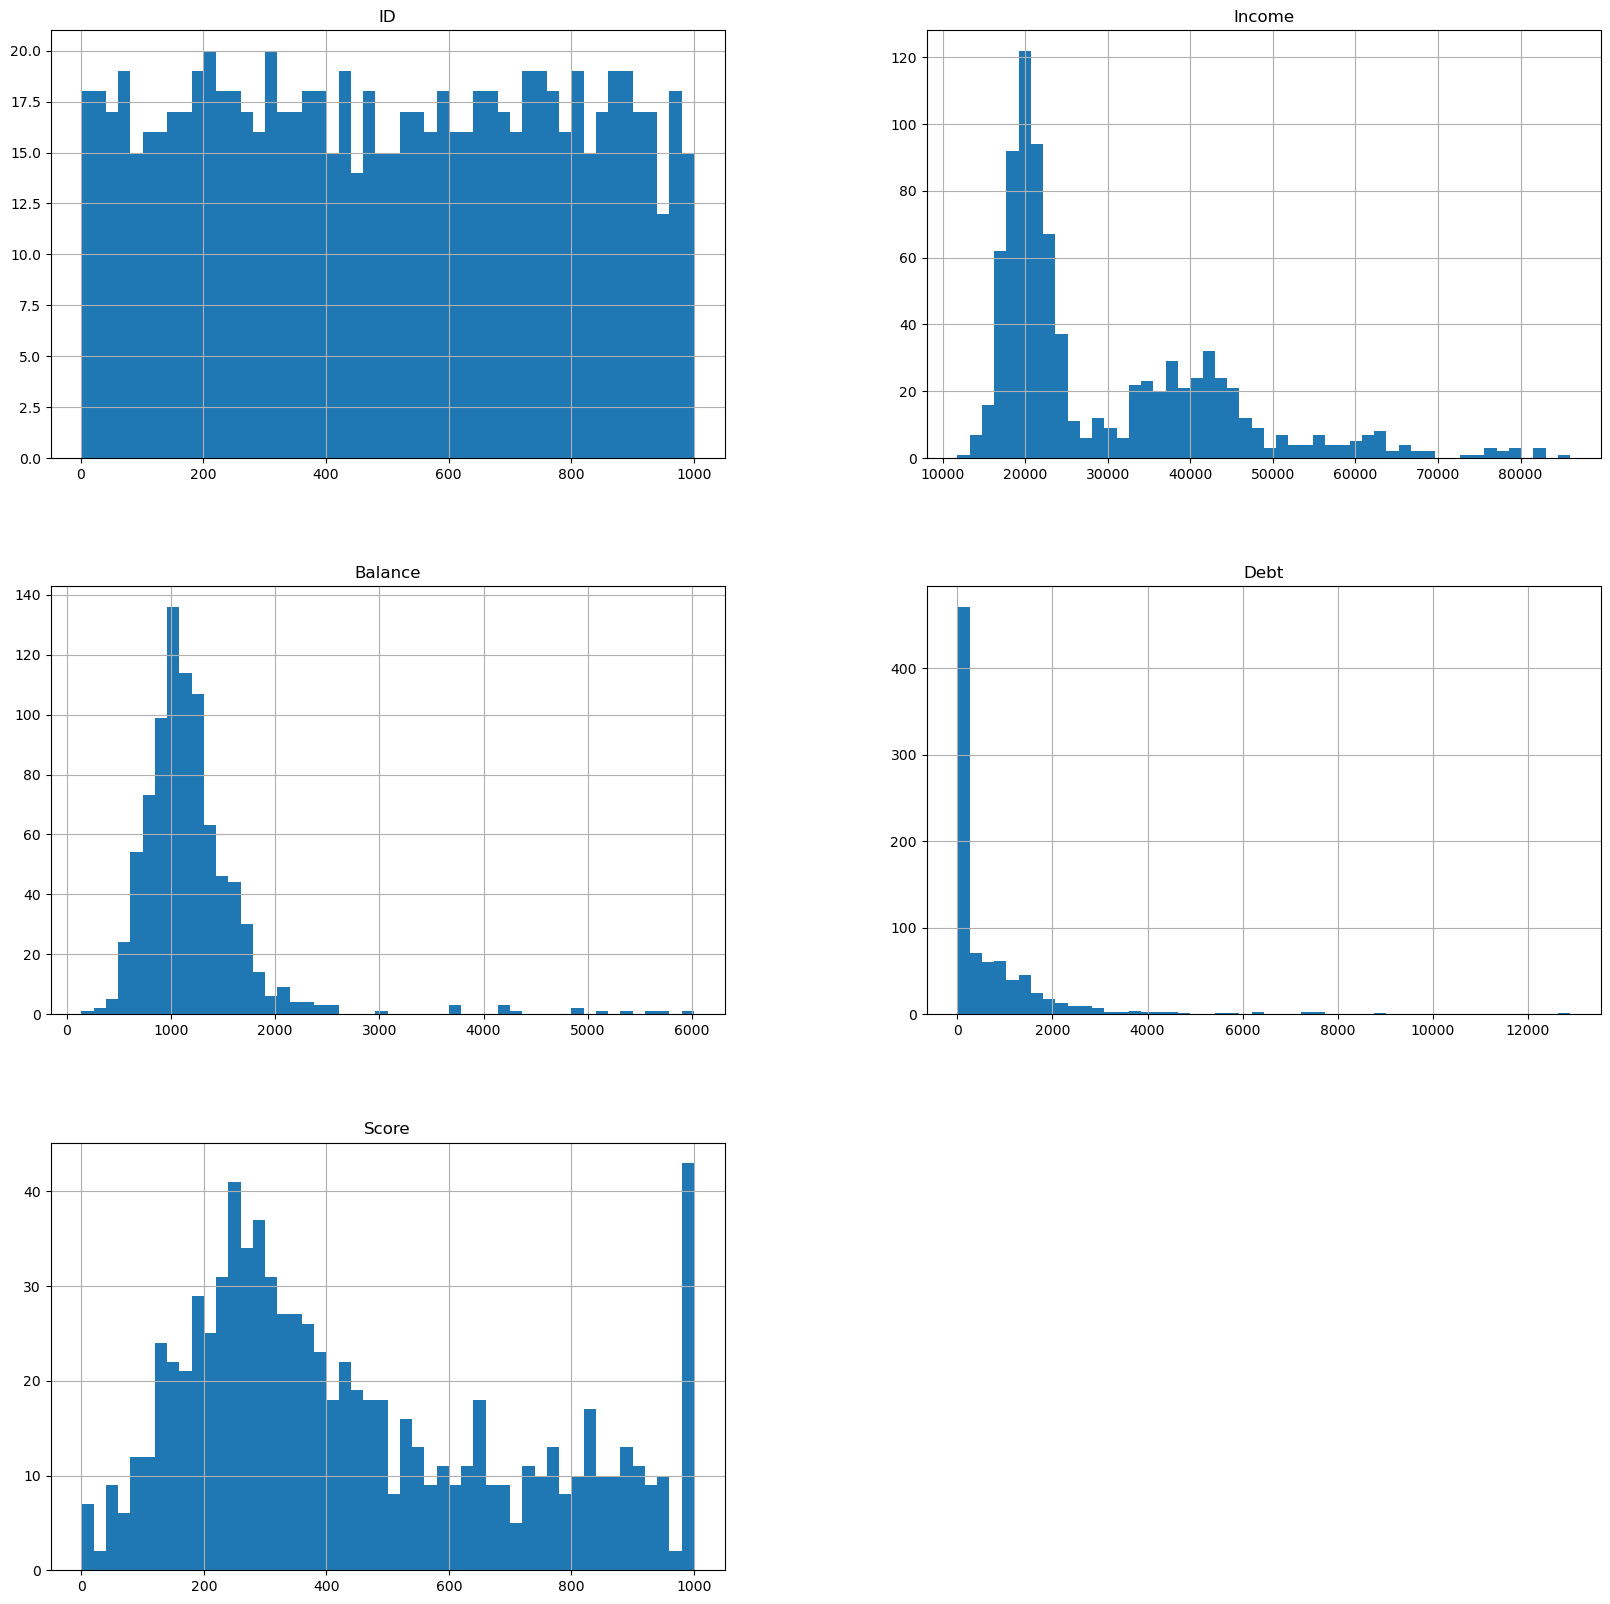

In [6]:
## visualising the distribution
df.hist(bins = 50, figsize=(20,20));

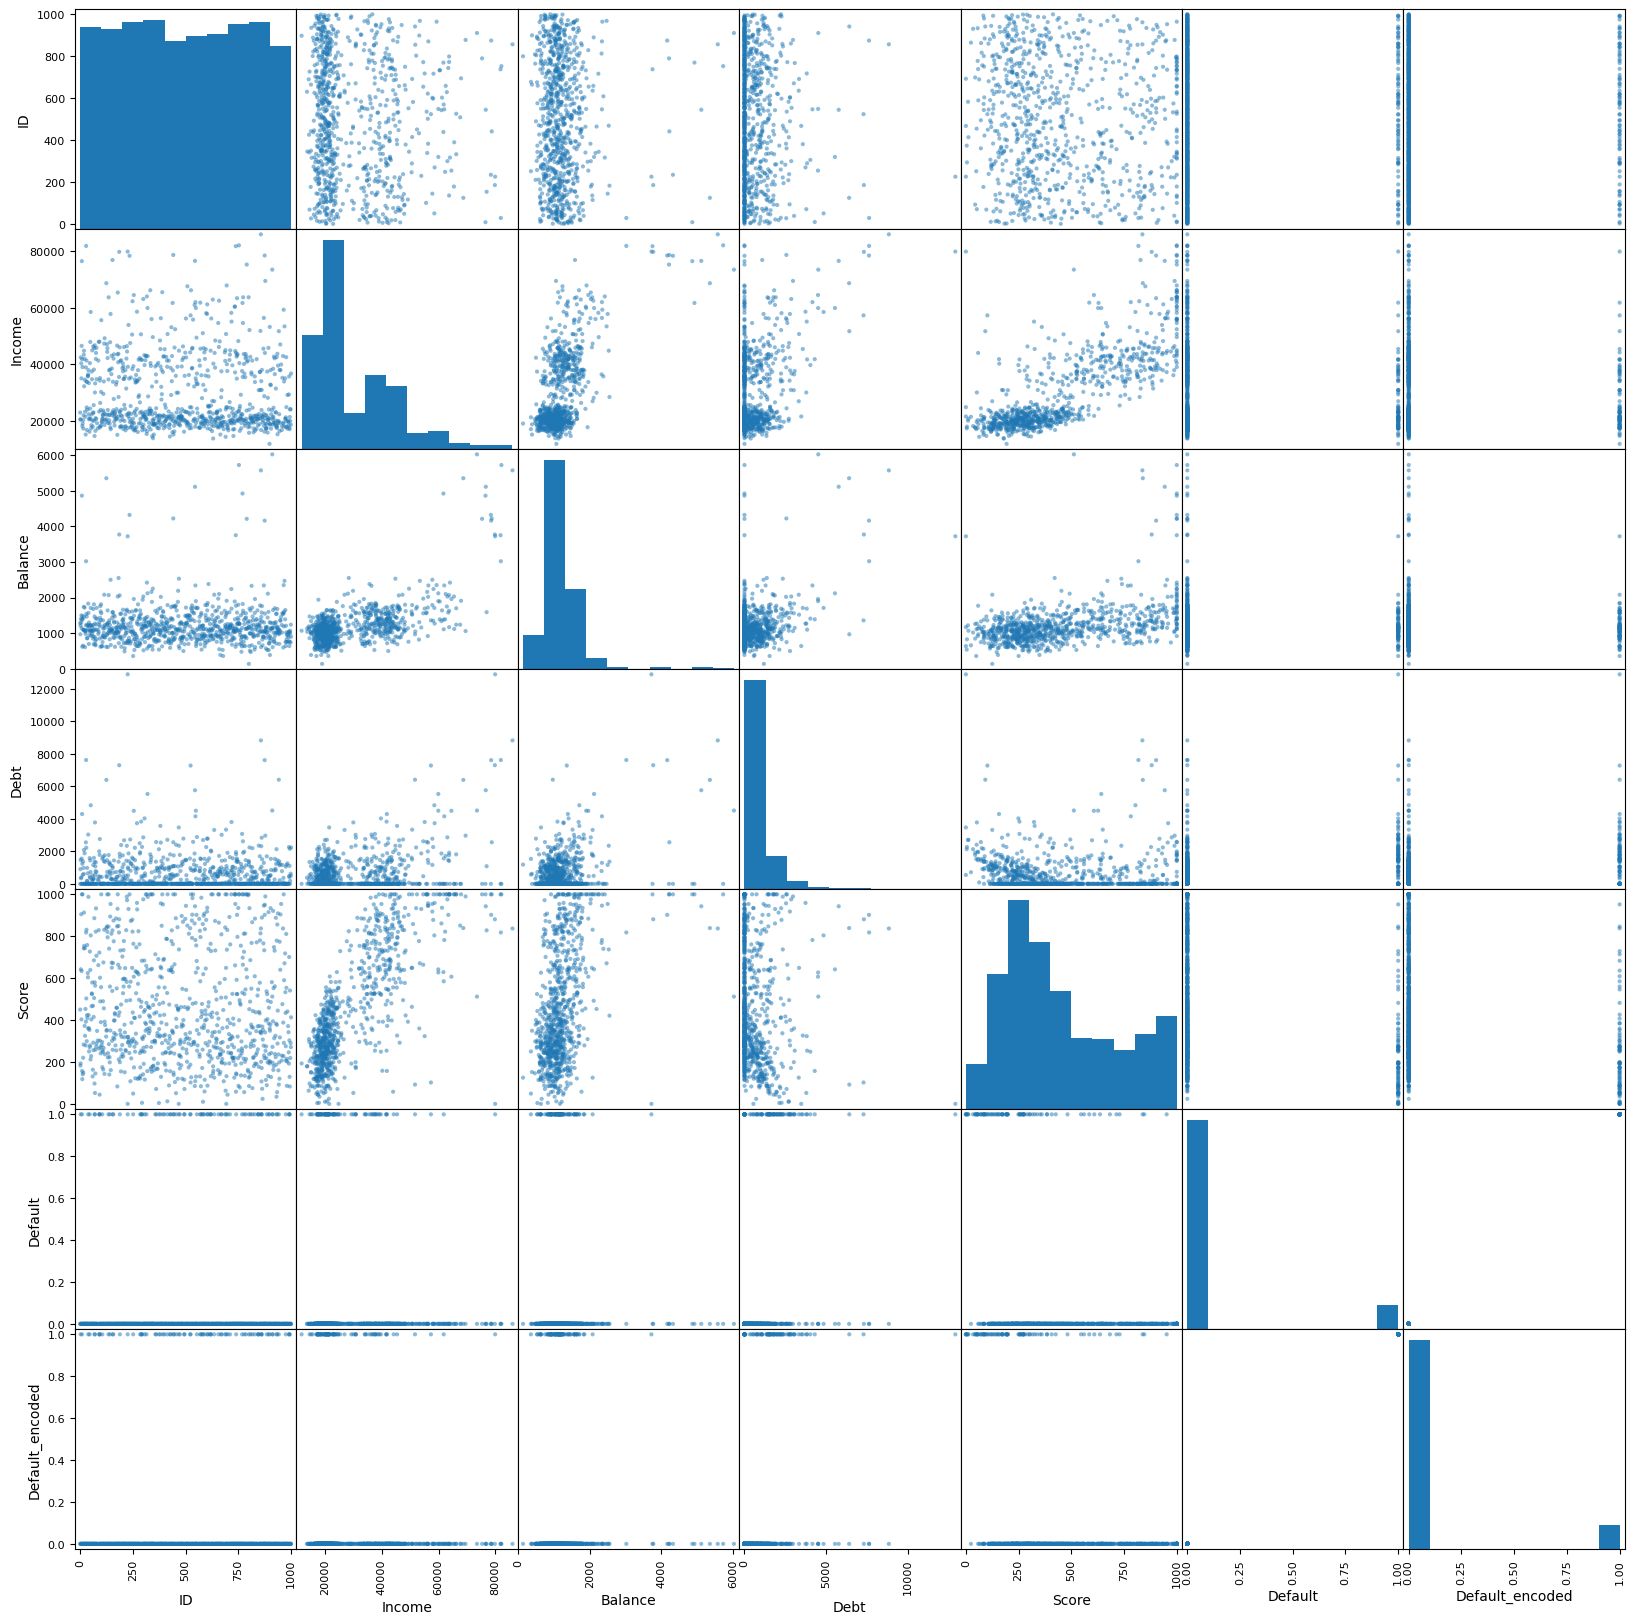

In [13]:
pd.plotting.scatter_matrix(df, figsize=(20,20));

In [7]:
## checking if there is any null values
df.isna().sum()

ID          0
Income      0
Term        0
Balance     0
Debt        0
Score      20
Default     0
dtype: int64

In [8]:
## looking at null values
df[df['Score'].isna()]


,ID,Income,Term,Balance,Debt,Score,Default
3,370,21600.0,Short Term,920.0,0.0,NaN,False
20,673,23500.0,Short Term,790.0,0.0,NaN,False
36,36,18500.0,Short Term,980.0,354.0,NaN,True
61,643,21300.0,Short Term,680.0,364.0,NaN,False
86,83,18400.0,Short Term,510.0,0.0,NaN,False
162,839,20700.0,Short Term,980.0,0.0,NaN,False
221,477,21500.0,Short Term,1300.0,1858.0,NaN,True
338,539,21600.0,Long Term,1180.0,738.0,NaN,False
357,714,20000.0,Short Term,1050.0,0.0,NaN,False
361,364,20800.0,Short Term,1030.0,115.0,NaN,False


In [9]:
## remove null values. Q= Why is dropping chosen over imputation
df.dropna(subset = ['Score'], how='all', inplace=True)

In [10]:
## Encoding target variable using label encoder
from sklearn.preprocessing import LabelEncoder

In [12]:
le = LabelEncoder()
df['Default_encoded'] = le.fit_transform(df['Default'])
print(df)


      ID   Income        Term  Balance    Debt  Score  Default  \
0    567  17500.0  Short Term   1460.0   272.0  225.0        0   
1    523  18500.0   Long Term    890.0   970.0  187.0        0   
2    544  20700.0  Short Term    880.0   884.0   85.0        0   
4    756  24300.0  Short Term   1260.0     0.0  495.0        0   
5    929  22900.0   Long Term   1540.0  1229.0  383.0        0   
..   ...      ...         ...      ...     ...    ...      ...   
851   71  30000.0   Long Term   1270.0  3779.0   52.0        1   
852  932  42500.0   Long Term   1550.0     0.0  779.0        0   
853   39  36400.0   Long Term   1830.0  3032.0  360.0        1   
854  283  42200.0   Long Term   1500.0  2498.0  417.0        0   
855  847  30800.0   Long Term   1190.0  2355.0  177.0        1   

     Default_encoded  
0                  0  
1                  0  
2                  0  
4                  0  
5                  0  
..               ...  
851                1  
852                0  


In [14]:
df.drop('Default', axis=1, inplace=True)

In [17]:
df.head()

,ID,Income,Term,Balance,Debt,Score,Default_encoded
0,567,17500.0,Short Term,1460.0,272.0,225.0,0
1,523,18500.0,Long Term,890.0,970.0,187.0,0
2,544,20700.0,Short Term,880.0,884.0,85.0,0
4,756,24300.0,Short Term,1260.0,0.0,495.0,0
5,929,22900.0,Long Term,1540.0,1229.0,383.0,0


In [19]:
## encoding categorical features using ordinal
from sklearn.preprocessing import OrdinalEncoder


In [20]:
## specifiying the order to encode
enc = OrdinalEncoder(categories = [['Short Term', 'Long Term']])

In [75]:
## Fitting to create a column for the data. Q= Why do we need to reshape into 2d?
df['Ordinal_encoded'] = enc.fit_transform(df['Term'].values.reshape(-1,1)) ##Error because i run this after Term was dropped

KeyError: 'Term'

In [29]:
df.head()

,ID,Income,Balance,Debt,Score,Default_encoded,Ordinal_encoded
0,567,17500.0,1460.0,272.0,225.0,0,0.0
1,523,18500.0,890.0,970.0,187.0,0,1.0
2,544,20700.0,880.0,884.0,85.0,0,0.0
4,756,24300.0,1260.0,0.0,495.0,0,0.0
5,929,22900.0,1540.0,1229.0,383.0,0,1.0


In [25]:
df.drop('Term', axis=1, inplace=True)

In [23]:
# Train test split
# Importing package
from sklearn.model_selection import train_test_split

In [30]:
cols = ['Income', 'Balance', 'Debt', 'Score', 'Ordinal_encoded']

In [31]:
#Splitting the data into test and train sets
X_train, X_test, y_train, y_test = train_test_split(df[cols],
                                                    df['Default_encoded'],
                                                    test_size=0.30,
                                                    random_state =42)

In [32]:
## scaling using standard scaler
cols_to_scale = ['Income', 'Balance', 'Debt', 'Score']

In [35]:
## scaling data = aid result interpretation (standardisation)
from sklearn.preprocessing import StandardScaler

# Calling the method twice, once for the features and once for the target
scaler =  StandardScaler()
# Fitting the scaler on the training features and applying it to both the training and test data
# Note how the Scaler is only fit to the training set, but then applied to both
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [77]:
## Building model using LinearRegression
from sklearn.linear_model import LogisticRegression

In [ ]:
cols = ['Income', 'Balance', 'Debt', 'Score', 'Ordinal_encoded']

In [78]:
## Create a LogisticRegression model. Then use the fit method to train the model on X_train and y_train. 
regressor = LogisticRegression()
regressor.fit(X_train[cols],y_train)
 # Carry out predictions on our test set
y_pred_lr = regressor.predict(X_test[cols])
y_pred_lr


array([0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0])

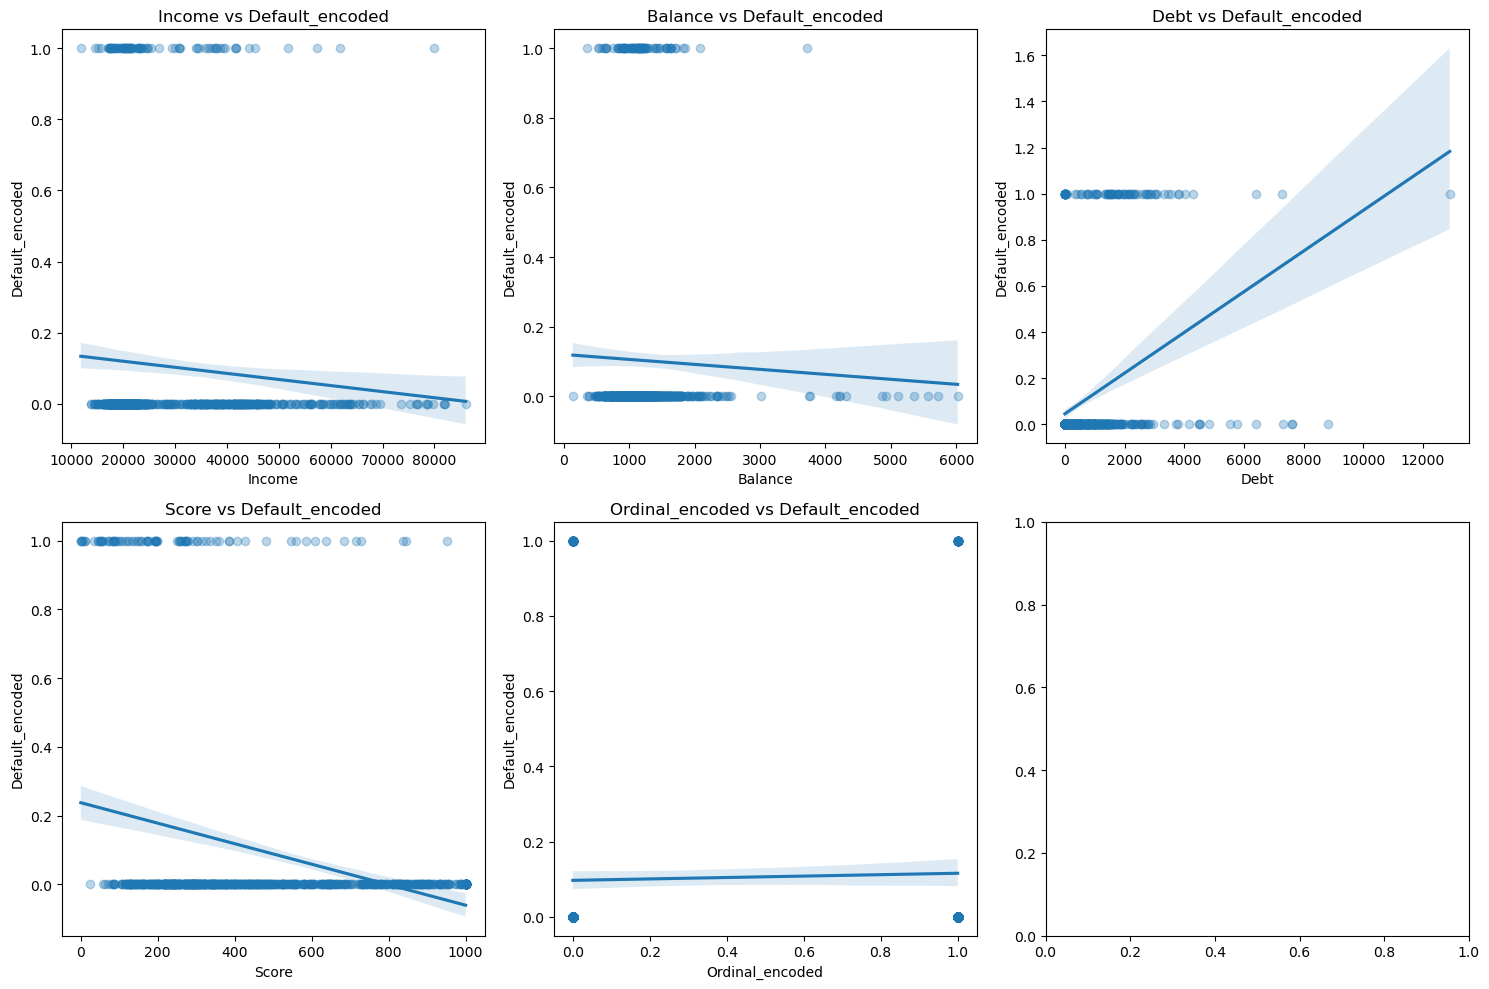

In [79]:

## viusalising
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(cols):
    sns.regplot(x=col, y='Default_encoded', data=df, ax=axes[i], scatter_kws={'alpha':0.3})
    axes[i].set_title(f'{col} vs Default_encoded')
plt.tight_layout()
plt.show()

In [ ]:
## Explanation subplot code
## plt.subplots(2, 3) = Creates a grid of 2 rows and 3 columns = 6subplots
## figsize=(15, 10) — Sets figure size to 15 inches wide, 10 inches tall
## fig, axes — Returns the figure object and array of axes (subplots)
## axes = axes.flatten() = Converts the 2D array axes (shape 2×3) into a 1D array for easier looping. Without this, you'd need nested loops to access axes[i][j]; now you just use axes[i]
## for i, col in enumerate(cols) = enumerate(cols) — Loop through each column with its index. i = index (0, 1, 2, ...), col = column name ('Income', 'Balance', etc.)
# sns.regplot(x=col, y='Default_encoded', data=df, ax=axes[i], scatter_kws={'alpha':0.3}). x=col, y='Default_encoded' — Plot feature vs target
## data=df — Use the full dataframe (before train/test split)
## ax=axes[i] — Draw on the i-th subplot
## scatter_kws={'alpha':0.3} — Make scatter points semi-transparent (30% opacity) so overlapping points are visible
## axes[i].set_title(f'{col} vs Default_encoded') = Adds a title to each subplot showing which feature it displays
## plt.tight_layout() = Automatically adjusts spacing between subplots so they don't overlap


In [43]:
## building a decision tree classifier model
from sklearn.tree import DecisionTreeClassifier

In [80]:
#creating an object from a class with params
clf = DecisionTreeClassifier(max_depth=2,min_samples_leaf=20,random_state=42)

In [81]:
#training (fitting) the classifier with the training set
clf.fit(X_train[cols],y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current n

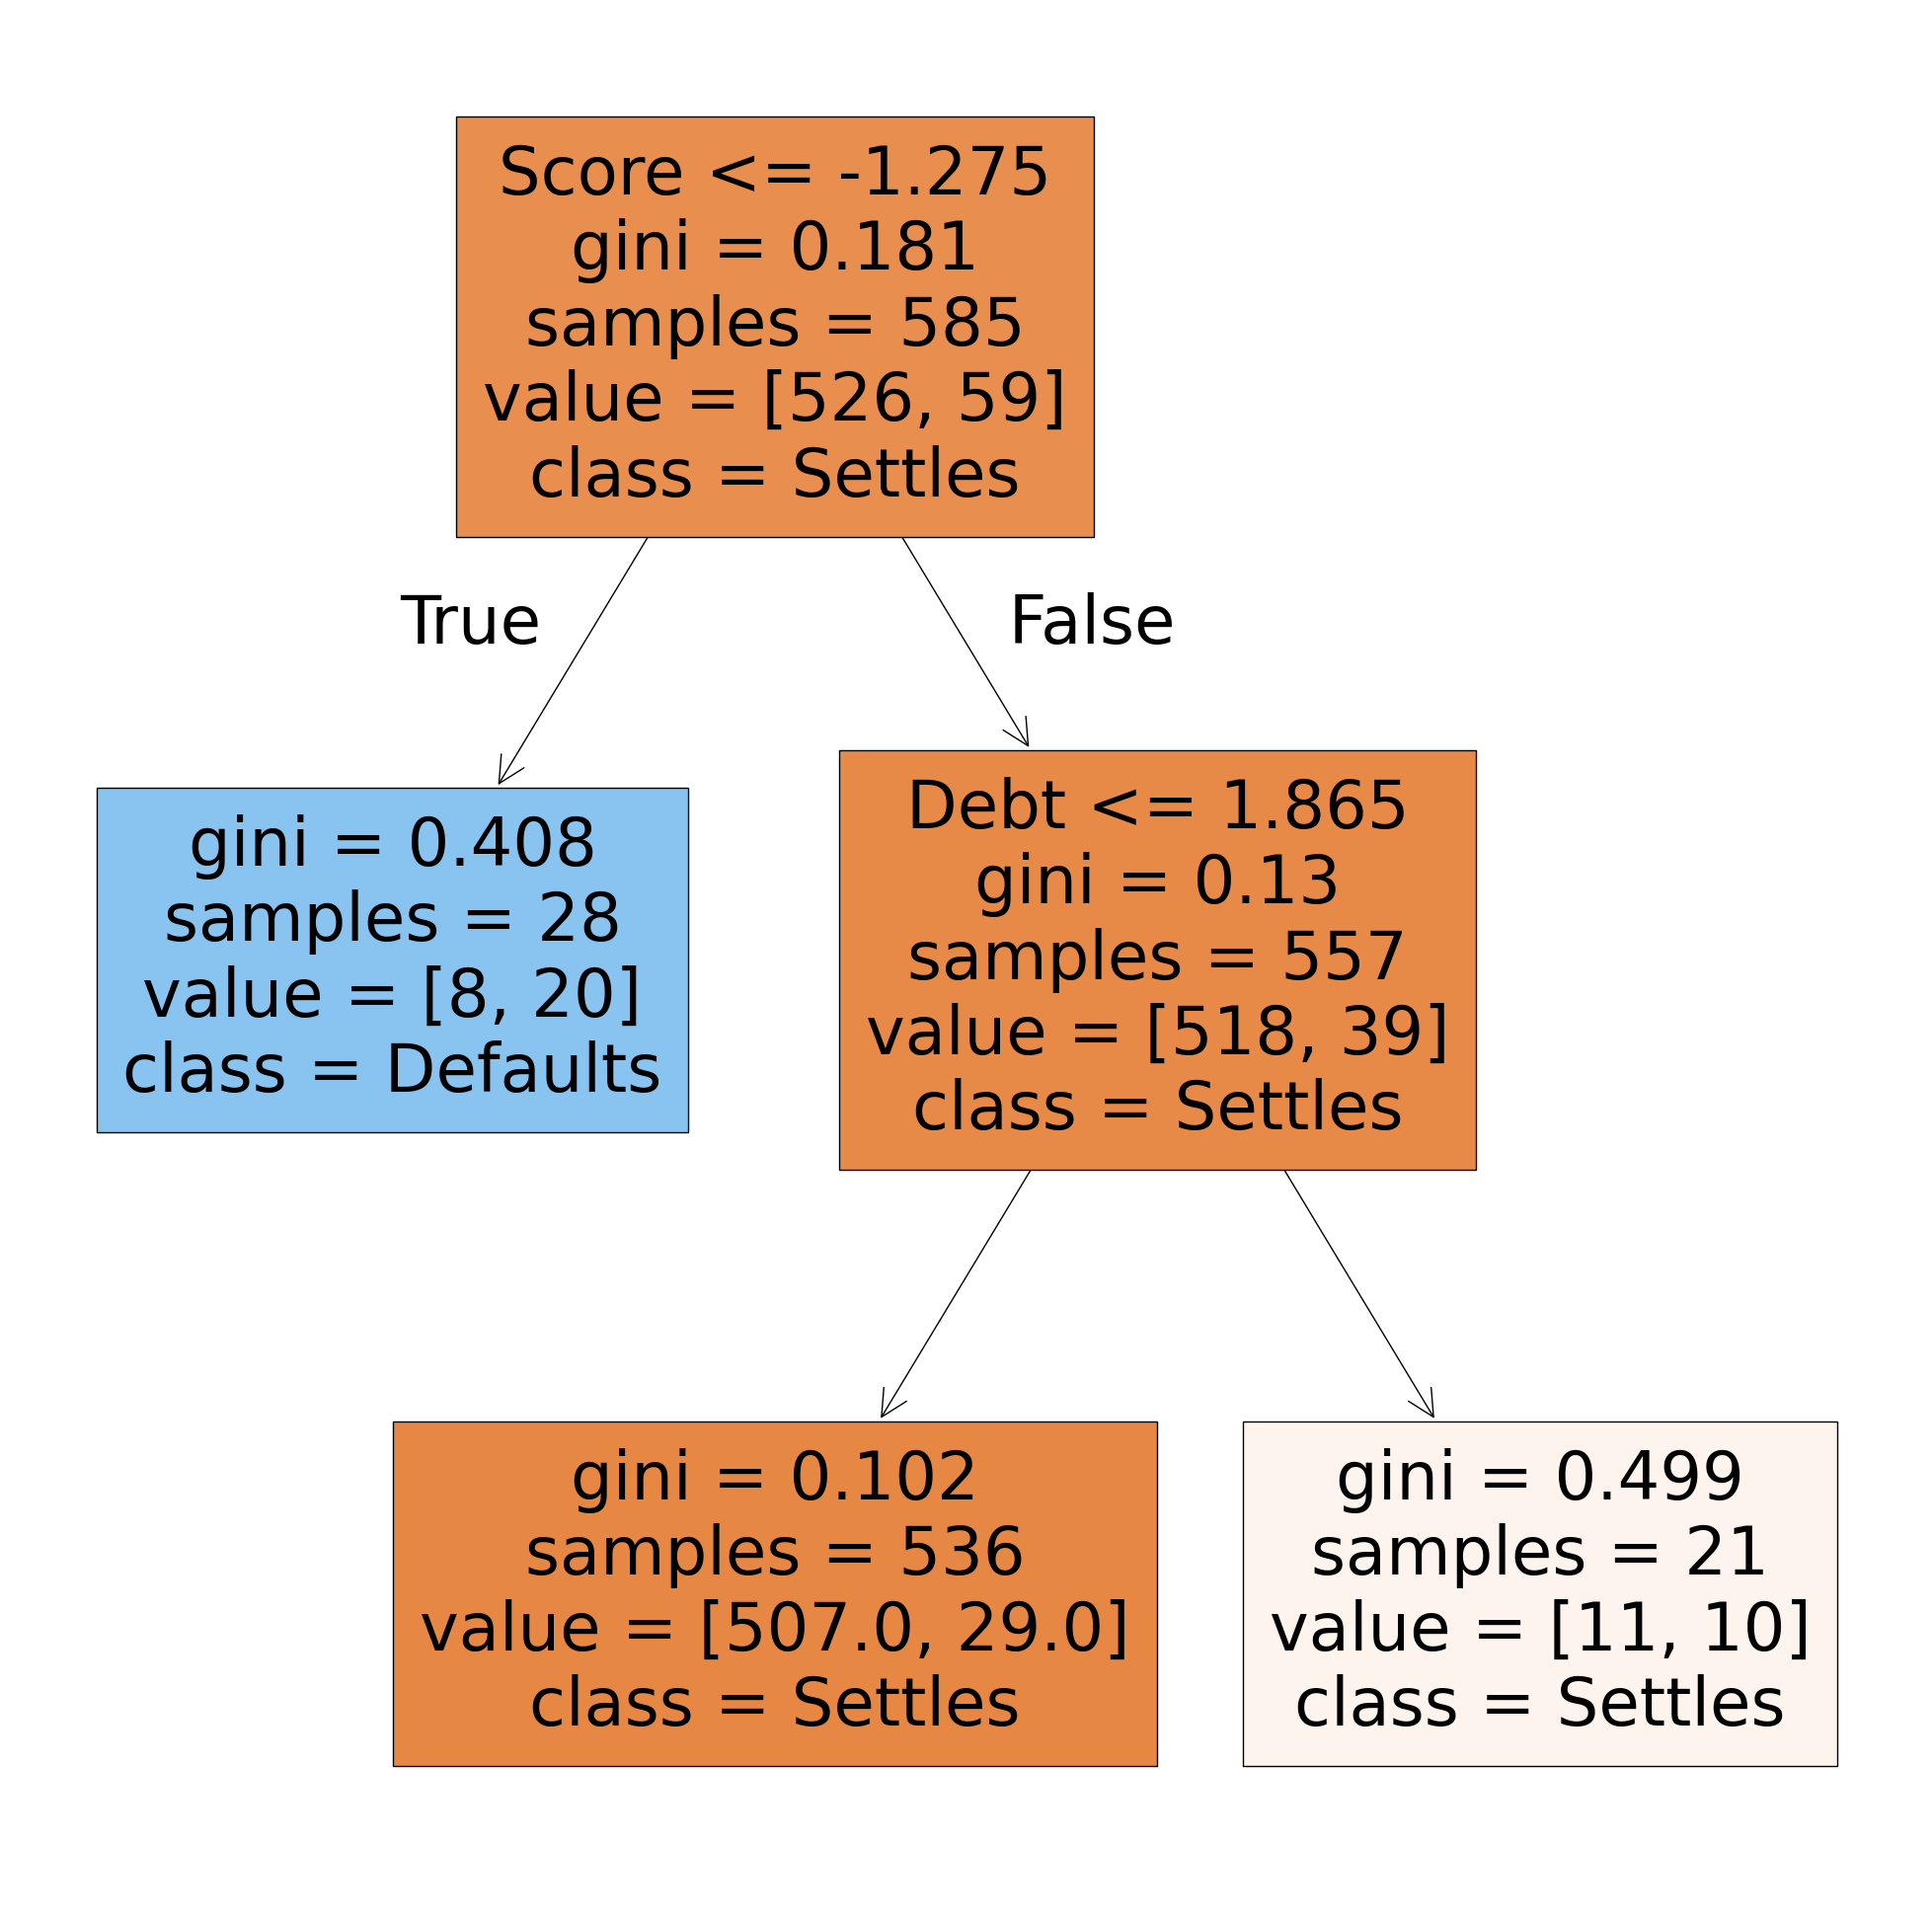

In [52]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

#Visualise
fig = plt.figure(figsize=(25,25))
tree_loan = plot_tree(clf,
                           feature_names =X_train[cols].columns ,
                           class_names= ['Settles', 'Defaults'],
                           filled= True )


In [ ]:
## TODO: Intepret the results above
'''
Baseline (root) node: gini = 0.181 with samples = 585 and value = [526, 59] — the majority class is "Settles". A Gini of 0.181 means the node is fairly pure (Gini ranges 0 = pure to 0.5 = maximally impure for binary).
Left child (Score <= -1.275, True): small node (samples = 28, gini = 0.408, value = [8,20]) — this subpopulation is Default-dominant (class = Defaults). The impurity is higher because the class mix is more even.
Right child (Score > -1.275): Debt <= 1.865 splits this large group. The left subtree of that split has gini = 0.102 (samples = 536, value = [507,29]) — a very pure Settles node. The right subtree is small and near-balanced (gini = 0.499, samples = 21, value = [11,10]) and should be treated with caution due to small sample size.
'''

           Feature  Importance
3            Score    0.754522
2             Debt    0.245478
0           Income    0.000000
1          Balance    0.000000
4  Ordinal_encoded    0.000000


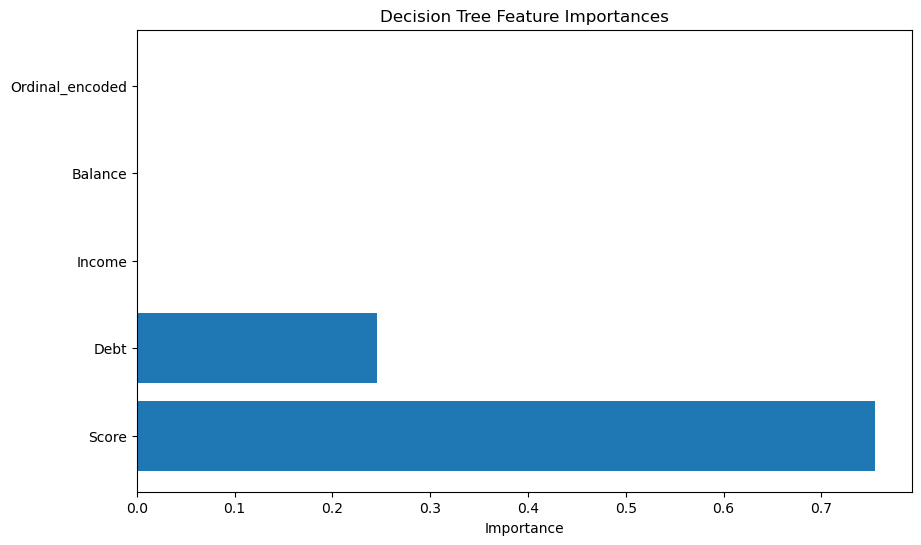

In [86]:
# feature importances - Which features the decision tree relied on the most to make predictions
importances = clf.feature_importances_
feature_names = clf.feature_names_in_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    "Importance": importances
}).sort_values('Importance', ascending=False)

print(importance_df)

# visualize as bar plot
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.xlabel('Importance')
plt.title('Decision Tree Feature Importances')
plt.show()

In [ ]:
'''What each does:

clf.feature_importances_ — Array of importance scores for each feature (how much each feature contributes to splits in the tree)
clf.feature_names_in_ — Array of feature names in the order they were used to train the model
sort_values('Importance', ascending=False) — Ranks features by importance (highest first)
'''

In [83]:
y_pred_clf = clf.predict(X_test[cols])

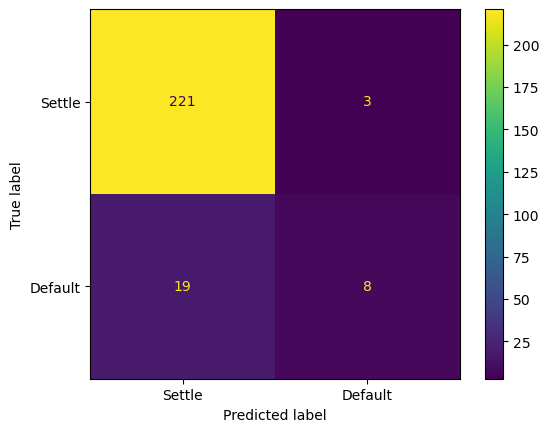

In [65]:
## Confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
predictions = clf.predict(X_test[cols])

cm = confusion_matrix(y_test,
predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
display_labels=('Settle','Default'))
disp.plot();



In [67]:
## random forest
from sklearn.ensemble import RandomForestClassifier

In [68]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train[cols],y_train)
y_pred_rf = rf.predict(X_test[cols])


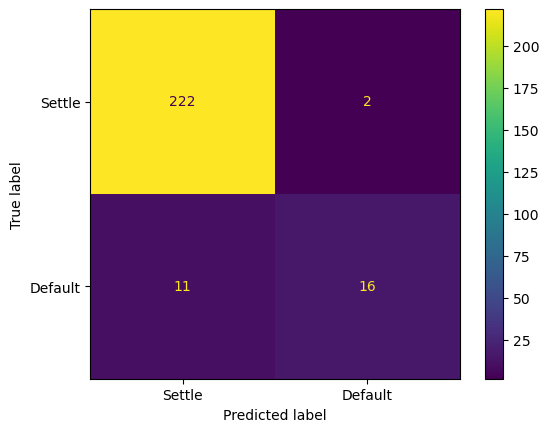

In [ ]:

# PLotting the confusion matrix
predictions = rf.predict(X_test[cols])
cm = confusion_matrix(y_test,
predictions,
labels=rf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
display_labels=('Settle','Default')
)
disp.plot()

In [ ]:
## Interpretation of confusion matrix above
'''

From the matrix (rows = true, cols = predicted):

* **True Settle → Pred Settle = 222 (correct)
* **True Settle → Pred Default = 2 (Settle misclassified as Default)
* **True Default → Pred Settle = 11 (Default misclassified as Settle)
* **True Default → Pred Default = 16 (correct)

### What that means

* ✅ **“Default has few examples” — yes. There are 27 Default cases (11+16) vs 224 Settle cases (222+2). Strong class imbalance.
* ✅ **“Default has high false negatives” — yes if you treat Default as the class of interest: FN(Default) = 11 (Default predicted as Settle). That’s 11/27 ≈ 41% missed Defaults → recall for Default ≈ 59%.
* ✅ **“Settle has high true positives” — yes: TP(Settle)=222, and Settle recall is 222/224 ≈ 99%.

One extra useful sentence: the model is very good at identifying Settle, but it misses a noticeable chunk of Defaults (Default recall ~59%), which may be a problem if Default is the important/rare class.


'''

           Feature  Importance
3            Score    0.344936
2             Debt    0.294463
0           Income    0.197344
1          Balance    0.145034
4  Ordinal_encoded    0.018222


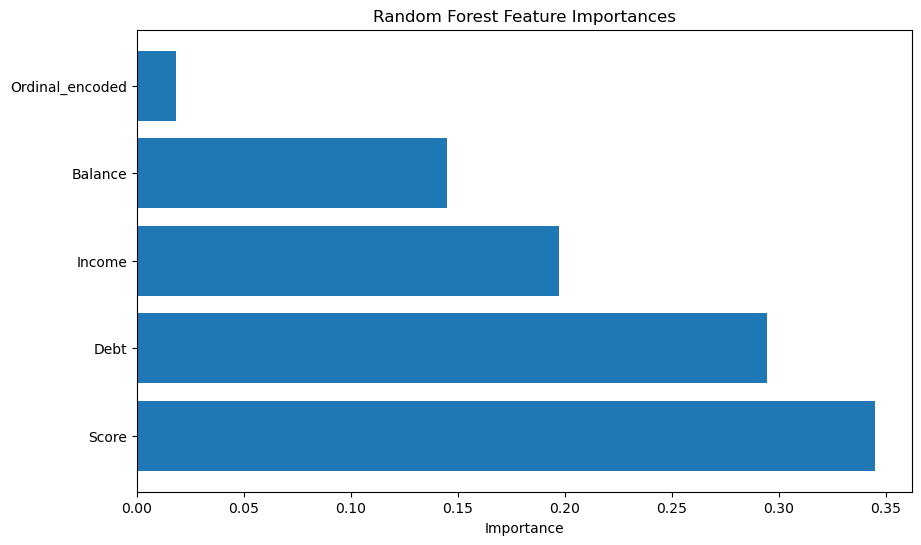

In [98]:
importances = rf.feature_importances_
feature_names = rf.feature_names_in_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    "Importance": importances
}).sort_values('Importance', ascending=False)

print(importance_df)

# visualize as bar plot
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.xlabel('Importance')
plt.title('Random Forest Feature Importances')
plt.show()

In [97]:
## Classification report for all models
## Evaluating the model
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

print("--Logistic Regression--")
print(classification_report(y_test, y_pred_lr, target_names=['Settles', 'Defaults']))

print("--Decision Tree--")
print(classification_report(y_test, y_pred_clf, target_names=['Settles', 'Defaults']))

print("--Random Forest--")
print(classification_report(y_test, y_pred_rf, target_names=['Settles', 'Defaults']))



--Logistic Regression--
              precision    recall  f1-score   support

     Settles       0.93      0.99      0.96       224
    Defaults       0.82      0.33      0.47        27

    accuracy                           0.92       251
   macro avg       0.87      0.66      0.72       251
weighted avg       0.91      0.92      0.90       251

--Decision Tree--
              precision    recall  f1-score   support

     Settles       0.92      0.99      0.95       224
    Defaults       0.73      0.30      0.42        27

    accuracy                           0.91       251
   macro avg       0.82      0.64      0.69       251
weighted avg       0.90      0.91      0.90       251

--Random Forest--
              precision    recall  f1-score   support

     Settles       0.95      0.99      0.97       224
    Defaults       0.89      0.59      0.71        27

    accuracy                           0.95       251
   macro avg       0.92      0.79      0.84       251
weighted avg  

In [ ]:
## TODO: Intepret the scores above
'''
Random Forest is the best model as it has the highest accuracy and f1 scores (precision and recall)
'''

In [89]:
## Receiver Operating Characteristics Curve
models = [clf, regressor, rf]


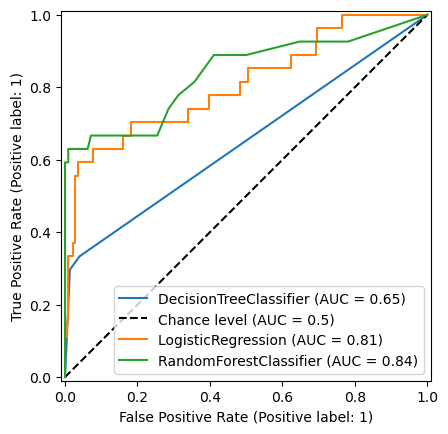

In [90]:
## ROC curve

from sklearn.metrics import RocCurveDisplay
for i, model in enumerate(models):
    if i == 0:
        plot = RocCurveDisplay.from_estimator(model,X_test[cols],y_test,plot_chance_level=True) 
        axes = plot.ax_
    else:
        RocCurveDisplay.from_estimator(model,X_test[cols],y_test,plot_chance_level=False,ax=axes)



In [ ]:
## TODO: Intepret the results above
'''
- All models have a good relative predictions rather than random
- Random Forest and LR perform similarly
'''